# Tarefa A — Agrupamento

Esta etapa usa as matrizes geradas por `transformacaoDados.ipynb` em `outputs/dados`. Os dois algoritmos escolhidos são o **K-Medoids** e o **Agrupamento Hierárquico Aglomerativo**. A análise principal usa `agrupamento_sem_gram`, com as 23 atividades e a morfologia, e deixa o `GRAM` livre para a validação externa. A matriz `agrupamento_com_gram` é usada só para medir o efeito de incluir essa coluna.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import pdist, squareform
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
    homogeneity_completeness_v_measure, normalized_mutual_info_score,
    silhouette_samples, silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

SEMENTE = 42
pasta_dados = Path("outputs/dados")
pasta_saida = Path("outputs/agrupamento")

def ler_tab(nome, **opcoes):
    return pd.read_csv(pasta_dados / f"{nome}.tab", sep="\t", encoding="utf-8-sig", **opcoes)

X_sem_gram = ler_tab("agrupamento_sem_gram")
X_com_gram = ler_tab("agrupamento_com_gram")
referencia = ler_tab("referencia_registros", dtype={"n°": "string", "GRAM": "string"})
limpos = pd.read_csv("Dados_REG_limpo.tab", sep="\t", encoding="utf-8-sig", dtype="string")
assert len(X_sem_gram) == len(X_com_gram) == len(referencia) == len(limpos)
assert referencia["n°"].equals(limpos["n°"])

atividades = [f"Atividade {i:02d}" for i in range(1, 24)]
morfologia = ["Cores", "Borda", "Textura", "Forma", "Brilho", "Muco", "Relevo"]
ensaios = (
    limpos[atividades].replace({"Negativo": "0", "Positivo": "1"})
    .apply(pd.to_numeric, errors="raise").astype("float64")
)

matriz = X_sem_gram.to_numpy()
distancias = squareform(pdist(matriz))
n_registros = len(matriz)

cores_grupos = ["#2a78d6", "#eb6834", "#1baf7a"]  # G1, G2, G3
tinta = "#3d3d3a"   # séries que representam métodos, não grupos
cinza = "#8a8a85"
print(f"Matriz principal: {matriz.shape[0]} registros e {matriz.shape[1]} atributos.")

Matriz principal: 506 registros e 73 atributos.


## Os dois métodos e suas premissas

**K-Medoids.** Escolhe *k* isolados reais como representantes (medoides) e atribui cada registro ao medoide mais próximo. O objetivo é minimizar a soma das distâncias de cada registro ao seu medoide. Como a soma usa a distância e não o seu quadrado, um registro muito afastado pesa menos do que pesaria no K-Means. O método supõe grupos compactos em torno de um isolado típico e exige definir *k*. Aceita qualquer medida de distância.

O scikit-learn não tem K-Medoids, e o pacote `scikit-learn-extra` não faz parte das dependências do projeto. Por isso a célula abaixo implementa o algoritmo PAM (*Partitioning Around Medoids*): parte de *k* medoides sorteados e, a cada passo, faz a troca entre um medoide e um não medoide que mais reduz o custo total, até nenhuma troca reduzir o custo. Como o resultado depende do sorteio inicial, rodamos 20 inicializações e ficamos com a de menor custo.

**Agrupamento Hierárquico Aglomerativo.** Começa com cada registro sozinho e, a cada passo, une os dois grupos mais próximos segundo um critério de ligação, até restar um único grupo. O resultado é um dendrograma, e o número de grupos vem do nível em que a árvore é cortada. Uma união nunca é desfeita, então um erro no começo se propaga até o fim.

**Distância.** Os dois métodos usam a distância euclidiana sobre a matriz pré-processada. Com a mesma geometria, a diferença entre as partições vem do algoritmo e não da medida de distância.

In [2]:
def k_medoids(D, k, semente, max_iter=200):
    # PAM: medoides iniciais sorteados e trocas enquanto o custo total cair.
    rng = np.random.default_rng(semente)
    n = len(D)
    medoides = rng.choice(n, size=k, replace=False)
    for _ in range(max_iter):
        dist_medoides = D[:, medoides]
        ordem = np.argsort(dist_medoides, axis=1)
        d1 = dist_medoides[np.arange(n), ordem[:, 0]]  # distância ao medoide mais próximo
        d2 = dist_medoides[np.arange(n), ordem[:, 1]]  # distância ao segundo mais próximo
        candidatos = np.setdiff1d(np.arange(n), medoides)
        D_candidatos = D[:, candidatos]
        melhor_variacao, melhor_troca = 0.0, None
        for posicao in range(k):
            do_grupo = (ordem[:, 0] == posicao)[:, None]
            # Ao remover este medoide, seus registros vão para o candidato ou para o segundo mais próximo.
            custo_troca = np.where(
                do_grupo,
                np.minimum(D_candidatos, d2[:, None]),
                np.minimum(D_candidatos, d1[:, None]),
            )
            variacao = custo_troca.sum(axis=0) - d1.sum()
            j = variacao.argmin()
            if variacao[j] < melhor_variacao - 1e-9:
                melhor_variacao, melhor_troca = variacao[j], (posicao, candidatos[j])
        if melhor_troca is None:
            break
        medoides[melhor_troca[0]] = melhor_troca[1]
    rotulos = D[:, medoides].argmin(axis=1)
    custo = D[np.arange(n), medoides[rotulos]].sum()
    return rotulos, medoides, custo

def melhor_k_medoids(D, k, inicializacoes=20, semente=SEMENTE):
    resultados = [k_medoids(D, k, semente + i) for i in range(inicializacoes)]
    return min(resultados, key=lambda resultado: resultado[2])

def soma_quadrados_intragrupo(X, rotulos):
    return sum(((X[rotulos == g] - X[rotulos == g].mean(axis=0)) ** 2).sum() for g in np.unique(rotulos))

### Critério de ligação

O critério de ligação define o que é "grupo mais próximo". A tabela mostra, para cada critério e cada *k*, a porcentagem dos 506 registros que fica no maior grupo, além da correlação cofenética, que mede o quanto as alturas do dendrograma preservam as distâncias originais.

In [3]:
ligacoes, cofeneticas = {}, {}
for metodo in ["ward", "complete", "average", "single"]:
    arvore = linkage(matriz, method=metodo)
    cofeneticas[metodo] = cophenet(arvore, pdist(matriz))[0]
    ligacoes[metodo] = {
        k: np.bincount(fcluster(arvore, k, criterion="maxclust")).max() / n_registros
        for k in range(2, 11)
    }

maior_grupo = pd.DataFrame(ligacoes).T
maior_grupo.columns = [f"k={k}" for k in maior_grupo.columns]
maior_grupo.insert(0, "Cofenética", pd.Series(cofeneticas).map(lambda v: f"{v:.2f}"))
for coluna in maior_grupo.columns[1:]:
    maior_grupo[coluna] = maior_grupo[coluna].map(lambda v: f"{v:.0%}")
print("Participação do maior grupo por critério de ligação")
print(maior_grupo.to_string())

Participação do maior grupo por critério de ligação
         Cofenética   k=2   k=3  k=4  k=5  k=6  k=7  k=8  k=9 k=10
ward           0.40   56%   44%  35%  35%  21%  19%  19%  18%  16%
complete       0.46   74%   69%  69%  40%  40%  29%  29%  29%  29%
average        0.57  100%   99%  99%  95%  94%  91%  91%  91%  91%
single         0.38  100%  100%  99%  99%  99%  99%  99%  98%  98%


As ligações média (*average*) e simples (*single*) deixam pelo menos 91% dos registros num único grupo em todos os valores de *k*. Elas separam primeiro alguns poucos registros afastados e encadeiam todo o resto, então não produzem uma partição útil, embora a média tenha a maior correlação cofenética (0,57). A ligação completa também concentra 69% dos registros num grupo com *k* = 3 e 4. O Ward é o único critério que divide a coleção em grupos de tamanho comparável, por isso é o usado a seguir.

O Ward une, a cada passo, os dois grupos cuja fusão menos aumenta a soma dos quadrados intragrupo. Ele exige a distância euclidiana e favorece grupos compactos e de variância parecida, uma premissa próxima da do K-Medoids. Mesmo assim, os dois métodos diferem em três pontos: o Ward nunca desfaz uma união, minimiza distâncias ao quadrado e representa o grupo pela média, enquanto o K-Medoids reatribui registros até convergir, soma distâncias sem elevar ao quadrado e representa o grupo por um isolado real.

## Escolha do número de grupos

Variamos *k* de 2 a 10. O cotovelo usa a função que cada método minimiza: a soma das distâncias aos medoides no K-Medoids e a soma dos quadrados intragrupo no Ward. A silhueta média é calculada com a mesma matriz de distâncias nos dois métodos.

    Custo K-Medoids  SQ intragrupo Ward  Silhueta K-Medoids  Silhueta Ward
k                                                                         
2            2669.3             10711.0               0.092          0.084
3            2535.3              9857.7               0.098          0.087
4            2460.6              9371.4               0.084          0.084
5            2407.6              9034.4               0.077          0.082
6            2362.8              8734.7               0.067          0.077
7            2325.6              8520.4               0.058          0.068
8            2295.4              8329.1               0.057          0.068
9            2269.0              8174.9               0.058          0.066
10           2245.1              8046.7               0.062          0.069


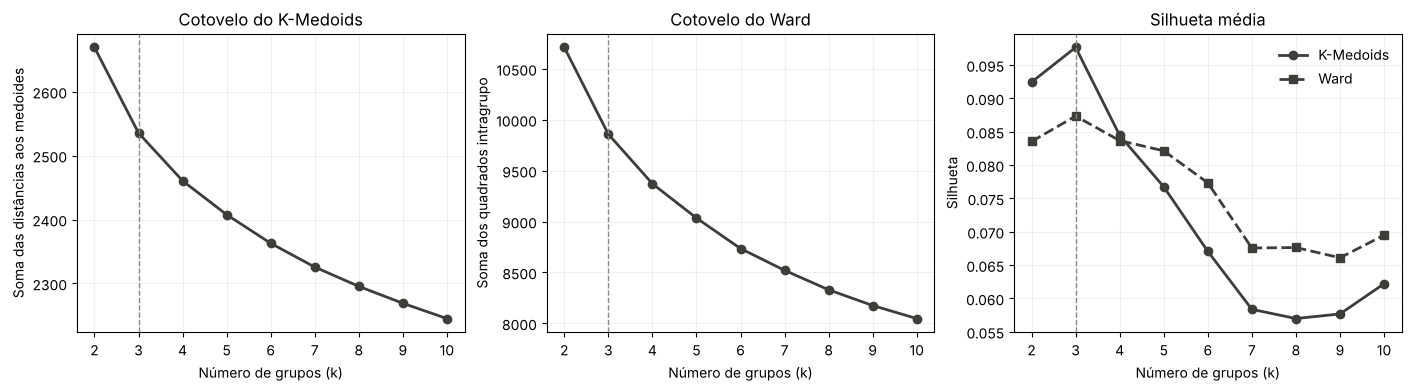

In [4]:
arvore_ward = linkage(matriz, method="ward")
faixa_k = range(2, 11)
linhas = []
for k in faixa_k:
    rotulos_km, _, custo = melhor_k_medoids(distancias, k)
    rotulos_hc = fcluster(arvore_ward, k, criterion="maxclust") - 1
    linhas.append({
        "k": k,
        "Custo K-Medoids": custo,
        "SQ intragrupo Ward": soma_quadrados_intragrupo(matriz, rotulos_hc),
        "Silhueta K-Medoids": silhouette_score(distancias, rotulos_km, metric="precomputed"),
        "Silhueta Ward": silhouette_score(distancias, rotulos_hc, metric="precomputed"),
    })
curvas = pd.DataFrame(linhas).set_index("k")
print(curvas.round({"Custo K-Medoids": 1, "SQ intragrupo Ward": 1, "Silhueta K-Medoids": 3, "Silhueta Ward": 3}).to_string())

K = 3
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
paineis = [
    ("Custo K-Medoids", "Cotovelo do K-Medoids", "Soma das distâncias aos medoides"),
    ("SQ intragrupo Ward", "Cotovelo do Ward", "Soma dos quadrados intragrupo"),
]
for ax, (coluna, titulo, rotulo_y) in zip(eixos, paineis):
    ax.plot(curvas.index, curvas[coluna], color=tinta, linewidth=2, marker="o", markersize=6)
    ax.set(title=titulo, xlabel="Número de grupos (k)", ylabel=rotulo_y)
ax = eixos[2]
for coluna, estilo, marcador, nome in [("Silhueta K-Medoids", "-", "o", "K-Medoids"), ("Silhueta Ward", "--", "s", "Ward")]:
    ax.plot(curvas.index, curvas[coluna], color=tinta, linestyle=estilo, linewidth=2,
            marker=marcador, markersize=6, label=nome)
ax.set(title="Silhueta média", xlabel="Número de grupos (k)", ylabel="Silhueta")
ax.legend(frameon=False)
for ax in eixos:
    ax.axvline(K, color=cinza, linestyle="--", linewidth=1)
    ax.set_xticks(list(faixa_k))
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
plt.show()

### Estabilidade para cada *k*

A silhueta e o cotovelo usam uma única partição para cada *k*. Para saber se a divisão se repete quando a amostra muda, sorteamos 20 subamostras com 80% dos registros e, para cada *k*, refazemos os dois agrupamentos em cada subamostra. O ARI compara o resultado de cada subamostra com a partição completa do mesmo *k*, nos registros sorteados. As mesmas 20 subamostras são usadas em todos os *k*, para que a comparação entre eles seja justa. O ponto marca a mediana e a barra vai do 1º ao 3º quartil.

Mediana do ARI em subamostras de 80%
Método  K-Medoids   Ward
k                       
2           0.611  0.178
3           0.703  0.346
4           0.564  0.396
5           0.653  0.390
6           0.623  0.461
7           0.636  0.440
8           0.603  0.456
9           0.656  0.462
10          0.631  0.486


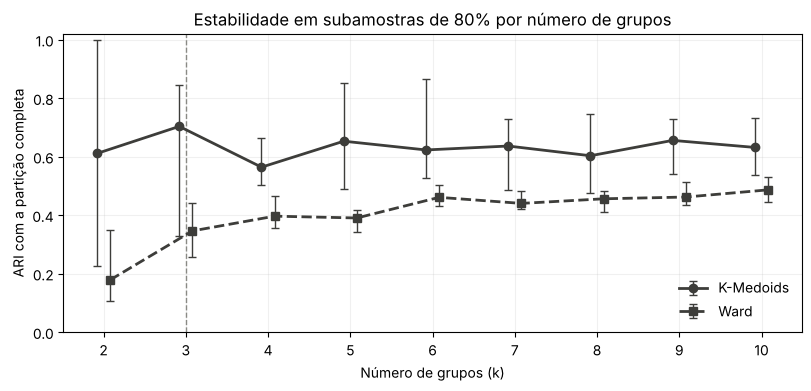

In [5]:
rng_k = np.random.default_rng(SEMENTE + 1)
subamostras = [np.sort(rng_k.choice(n_registros, size=int(0.8 * n_registros), replace=False)) for _ in range(20)]
linhas = []
for k in faixa_k:
    completa_km = melhor_k_medoids(distancias, k)[0]
    completa_hc = fcluster(arvore_ward, k, criterion="maxclust")
    for repeticao, indices in enumerate(subamostras):
        sub_km = melhor_k_medoids(distancias[np.ix_(indices, indices)], k, inicializacoes=5, semente=3000 + 10 * repeticao)[0]
        sub_hc = fcluster(linkage(matriz[indices], method="ward"), k, criterion="maxclust")
        linhas.append({"k": k, "Método": "K-Medoids", "ARI": adjusted_rand_score(completa_km[indices], sub_km)})
        linhas.append({"k": k, "Método": "Ward", "ARI": adjusted_rand_score(completa_hc[indices], sub_hc)})
estabilidade_k = pd.DataFrame(linhas)
resumo_k = estabilidade_k.groupby(["k", "Método"])["ARI"].quantile([0.25, 0.5, 0.75]).unstack().unstack("Método")
tabela_k = estabilidade_k.groupby(["k", "Método"])["ARI"].median().unstack()
print("Mediana do ARI em subamostras de 80%")
print(tabela_k.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
for metodo, estilo, marcador, deslocamento in [("K-Medoids", "-", "o", -0.08), ("Ward", "--", "s", 0.08)]:
    x = np.array(list(faixa_k)) + deslocamento
    mediana = resumo_k[(0.5, metodo)]
    ax.errorbar(
        x, mediana,
        yerr=[mediana - resumo_k[(0.25, metodo)], resumo_k[(0.75, metodo)] - mediana],
        color=tinta, linestyle=estilo, marker=marcador, markersize=6, linewidth=2,
        capsize=3, elinewidth=1, label=metodo,
    )
ax.axvline(K, color=cinza, linestyle="--", linewidth=1)
ax.set(xlabel="Número de grupos (k)", ylabel="ARI com a partição completa", ylim=(0, 1.02),
       title="Estabilidade em subamostras de 80% por número de grupos")
ax.set_xticks(list(faixa_k))
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.18)
ax.set_axisbelow(True)
plt.show()

**Cotovelo.** As duas curvas caem de forma suave, sem uma dobra nítida. A maior queda relativa ocorre de *k* = 2 para *k* = 3: no K-Medoids o custo cai 134, contra 75 de 3 para 4; no Ward a soma dos quadrados cai 853, contra 486. A partir daí as quedas diminuem gradualmente.

**Silhueta.** Os dois métodos têm a maior silhueta média em *k* = 3 (0,098 no K-Medoids e 0,087 no Ward).

**Estabilidade.** O *k* = 2 é o menos confiável nos dois métodos. No Ward, tem a pior mediana (0,18). No K-Medoids, a mediana é 0,61, mas o ARI vai de 0,23 a 1,00 entre o 1º e o 3º quartil: em algumas subamostras a divisão em dois grupos se repete igual e em outras sai completamente diferente. No K-Medoids, o *k* = 3 tem a maior mediana de todos os valores testados (0,70). No Ward, a mediana cresce devagar com *k*, de 0,35 em *k* = 3 até 0,49 em *k* = 10, sem chegar a 0,5 em nenhum caso. Esse pequeno ganho não compensa a queda da silhueta, que diminui a partir de *k* = 4.

Juntando os três critérios, escolhemos **k = 3** para os dois métodos. Os valores são baixos em todos os *k*: uma silhueta abaixo de 0,1 indica que os registros estão quase tão perto do grupo vizinho quanto do próprio. A coleção não forma grupos bem separados, e os grupos encontrados devem ser lidos como regiões de um contínuo de perfis.

## Partições finais

Os grupos do K-Medoids são numerados do maior para o menor. Os grupos do Ward recebem o número do grupo do K-Medoids com que mais compartilham registros, para que a mesma cor indique o grupo correspondente nos dois métodos.

Tamanho dos grupos
    K-Medoids  Ward
G1        194   107
G2        183   223
G3        129   176

Medoides do K-Medoids (isolados representativos):
  n°     GRAM Grupo
1722 Positivo    G1
1477 Positivo    G2
1855 Positivo    G3


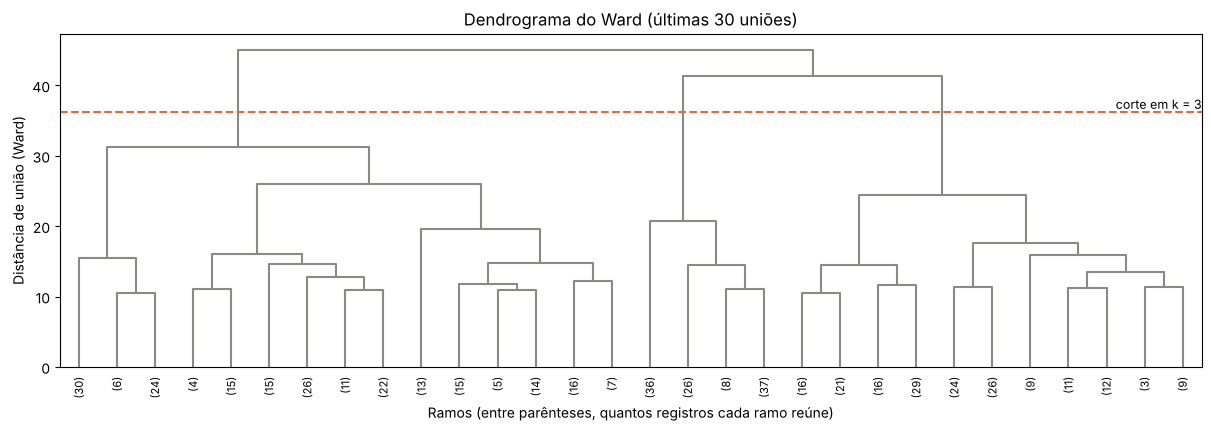

In [6]:
def alinhar(rotulos, rotulos_referencia):
    tabela = pd.crosstab(rotulos, rotulos_referencia)
    linhas, colunas = linear_sum_assignment(-tabela.to_numpy())
    mapa = dict(zip(tabela.index[linhas], tabela.columns[colunas]))
    return np.array([mapa[r] for r in rotulos])

rotulos_km, medoides, custo_km = melhor_k_medoids(distancias, K)
ordem_tamanho = pd.Series(rotulos_km).value_counts().index.to_numpy()
rotulos_km = np.argsort(ordem_tamanho)[rotulos_km]
medoides = medoides[ordem_tamanho]
rotulos_hc = alinhar(fcluster(arvore_ward, K, criterion="maxclust") - 1, rotulos_km)

nomes_grupos = [f"G{g + 1}" for g in range(K)]
tamanhos = pd.DataFrame({
    "K-Medoids": np.bincount(rotulos_km, minlength=K),
    "Ward": np.bincount(rotulos_hc, minlength=K),
}, index=nomes_grupos)
print("Tamanho dos grupos")
print(tamanhos.to_string())
print("\nMedoides do K-Medoids (isolados representativos):")
print(limpos.loc[medoides, ["n°", "GRAM"]].assign(Grupo=nomes_grupos).to_string(index=False))

altura_corte = arvore_ward[-K:-K + 2, 2].mean()
fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
dendrogram(
    arvore_ward, truncate_mode="lastp", p=30, ax=ax, color_threshold=0,
    above_threshold_color=cinza, leaf_rotation=90, leaf_font_size=8,
)
ax.axhline(altura_corte, color=cores_grupos[1], linestyle="--", linewidth=1.5)
ax.text(ax.get_xlim()[1], altura_corte, f" corte em k = {K}", va="bottom", ha="right", fontsize=9)
ax.set(
    title="Dendrograma do Ward (últimas 30 uniões)",
    xlabel="Ramos (entre parênteses, quantos registros cada ramo reúne)",
    ylabel="Distância de união (Ward)",
)
plt.show()

O K-Medoids gera grupos de 194, 183 e 129 registros. O Ward gera grupos mais desiguais, de 107, 223 e 176. No dendrograma, a primeira divisão do Ward separa o ramo da esquerda, que reúne 223 registros e corresponde ao G2, do resto da coleção. A segunda divisão separa o G1 (107) do G3 (176). As alturas das uniões acima e abaixo do corte (45, 41 e depois 31) diminuem aos poucos, sem um salto grande que indique um número natural de grupos, o que confirma a leitura da silhueta.

## Métricas internas

Usamos três métricas internas: silhueta (quanto maior, melhor), Davies-Bouldin (quanto menor, melhor) e Calinski-Harabasz (quanto maior, melhor). A figura mostra a silhueta de cada registro, ordenada dentro de cada grupo. Valores negativos indicam registros mais próximos, em média, de outro grupo do que do próprio.

          Silhueta média Davies-Bouldin Calinski-Harabasz Registros com silhueta negativa
K-Medoids          0.098          2.547            53.388                           11.7%
Ward               0.087          2.679            47.687                           17.2%

Silhueta média por grupo
    K-Medoids   Ward
G1      0.091  0.164
G2      0.086  0.047
G3      0.124  0.091


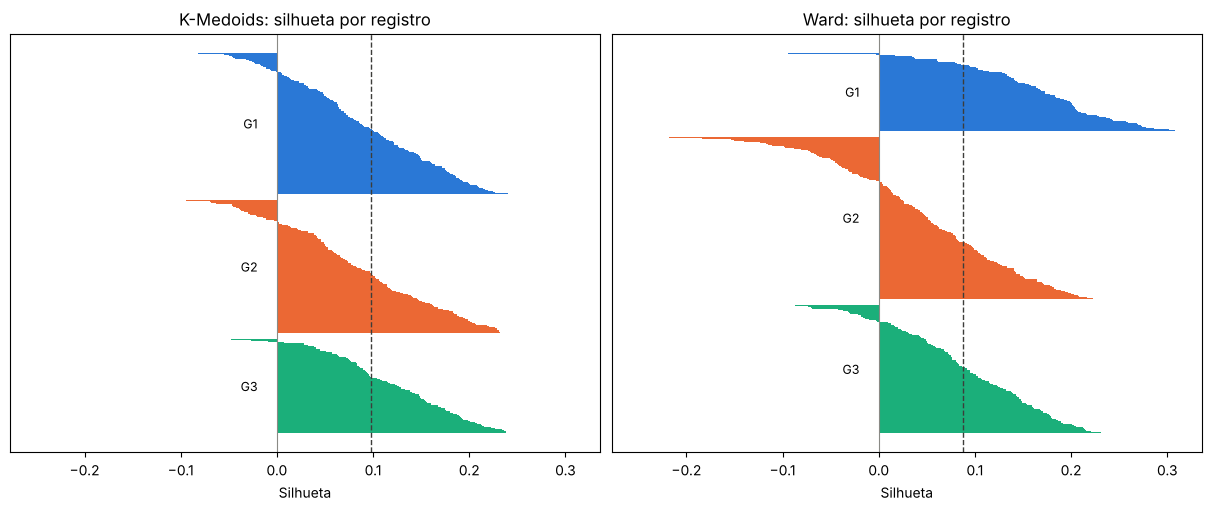

In [7]:
def metricas_internas(rotulos):
    silhuetas = silhouette_samples(distancias, rotulos, metric="precomputed")
    return {
        "Silhueta média": silhuetas.mean(),
        "Davies-Bouldin": davies_bouldin_score(matriz, rotulos),
        "Calinski-Harabasz": calinski_harabasz_score(matriz, rotulos),
        "Registros com silhueta negativa": f"{(silhuetas < 0).mean():.1%}",
    }

particoes = {"K-Medoids": rotulos_km, "Ward": rotulos_hc}
internas = pd.DataFrame({nome: metricas_internas(rotulos) for nome, rotulos in particoes.items()}).T
print(internas.to_string(float_format=lambda v: f"{v:.3f}"))

silhueta_por_grupo = pd.DataFrame({
    nome: pd.Series(silhouette_samples(distancias, rotulos, metric="precomputed")).groupby(rotulos).mean()
    for nome, rotulos in particoes.items()
})
silhueta_por_grupo.index = nomes_grupos
print("\nSilhueta média por grupo")
print(silhueta_por_grupo.round(3).to_string())

fig, eixos = plt.subplots(1, 2, figsize=(12, 5), sharex=True, layout="constrained")
for ax, (nome, rotulos) in zip(eixos, particoes.items()):
    silhuetas = silhouette_samples(distancias, rotulos, metric="precomputed")
    base = 0
    for g in range(K):
        valores = np.sort(silhuetas[rotulos == g])
        ax.barh(np.arange(base, base + len(valores)), valores, height=1.0, color=cores_grupos[g], linewidth=0)
        ax.text(-0.02, base + len(valores) / 2, nomes_grupos[g], ha="right", va="center", fontsize=9)
        base += len(valores) + 8
    ax.axvline(silhuetas.mean(), color=tinta, linestyle="--", linewidth=1)
    ax.axvline(0, color=cinza, linewidth=0.8)
    ax.set(title=f"{nome}: silhueta por registro", xlabel="Silhueta", yticks=[])
    ax.invert_yaxis()
plt.show()

O K-Medoids é melhor nas três métricas: tem silhueta maior (0,098 contra 0,087), Davies-Bouldin menor (2,55 contra 2,68) e Calinski-Harabasz maior (53,4 contra 47,7). Isso é esperado, porque o K-Medoids ajusta a partição inteira até convergir, enquanto o Ward toma decisões gulosas que não pode desfazer. As métricas internas favorecem grupos compactos, o que também beneficia os dois métodos de forma parecida.

Na figura, todos os grupos têm silhuetas entre −0,2 e 0,3, sem nenhum grupo claramente coeso. No Ward, o G2 concentra a maioria dos valores negativos (média de 0,047) e 17,2% dos registros do Ward têm silhueta negativa, contra 11,7% no K-Medoids. O G1 do Ward é o grupo mais coeso dos dois métodos (0,164), porque reúne só o núcleo de 107 registros com o perfil mais marcado.

## Caracterização dos grupos

O mapa de calor mostra, para cada atividade, a diferença entre a média do grupo e a média geral, medida em desvios padrão da coluna. Vermelho indica resposta acima da média da coleção e azul, abaixo. As atividades binárias também são padronizadas aqui para ficarem na mesma escala visual. A tabela seguinte traz as médias na escala original, calculadas com os valores observados antes da imputação.

Média das atividades na escala original (valores observados)
             K-Medoids                 Ward               Coleção
                    G1     G2     G3     G1     G2     G3   Todos
Atividade 01      0.03   0.02   0.09   0.00   0.03   0.09    0.04
Atividade 02      1.74   0.38   0.56   2.49   0.43   0.67    0.95
Atividade 03      0.10   0.04   0.01   0.10   0.06   0.02    0.06
Atividade 04      0.02   0.07   0.03   0.01   0.05   0.04    0.04
Atividade 05      0.83   0.75   0.46   0.93   0.70   0.59    0.71
Atividade 06      0.02   0.19   0.05   0.00   0.16   0.05    0.09
Atividade 07      0.13   0.13   0.09   0.15   0.13   0.09    0.12
Atividade 08      0.02   0.01   0.02   0.03   0.01   0.02    0.02
Atividade 09      0.55   0.77   0.91   0.51   0.69   0.90    0.72
Atividade 10      0.34   0.50   0.51   0.29   0.47   0.50    0.44
Atividade 11      0.20   0.30   0.35   0.18   0.26   0.35    0.27
Atividade 12      0.15   0.19   0.26   0.14   0.17   0.26    0.19
Atividade 13   

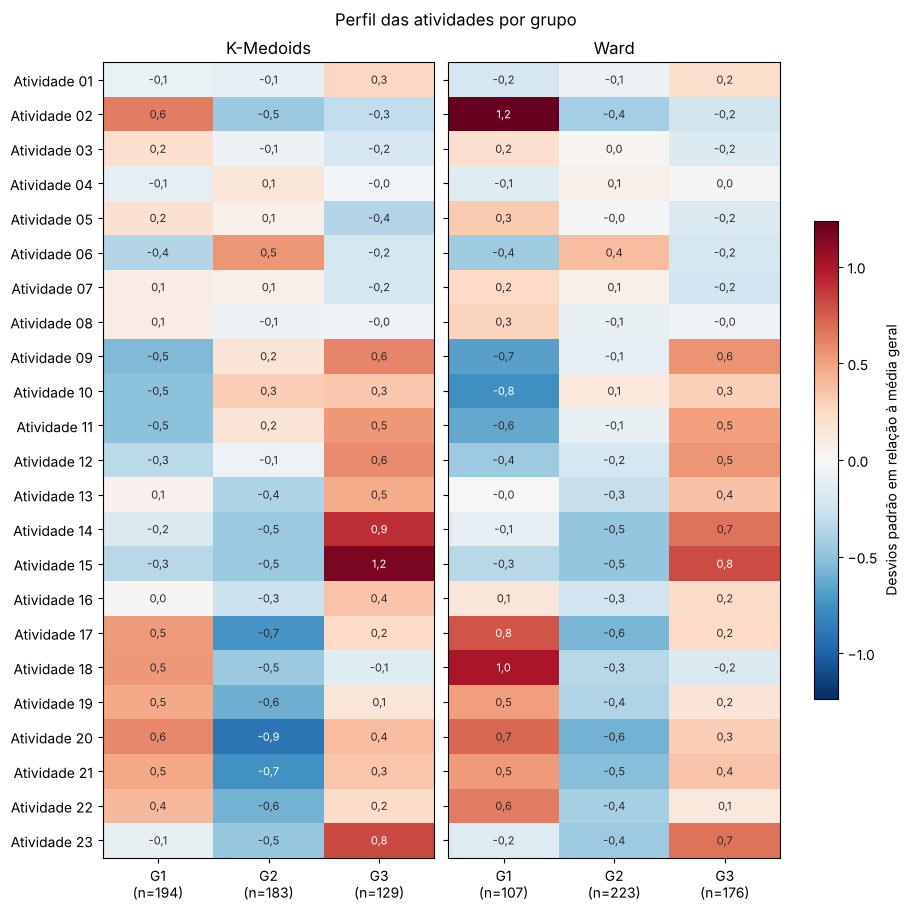

In [8]:
padronizadas = (X_sem_gram[atividades] - X_sem_gram[atividades].mean()) / X_sem_gram[atividades].std(ddof=0)
perfis = {nome: padronizadas.groupby(rotulos).mean().T for nome, rotulos in particoes.items()}
limite = max(np.abs(perfil.to_numpy()).max() for perfil in perfis.values())

fig, eixos = plt.subplots(1, 2, figsize=(9, 9), sharey=True, layout="constrained")
for ax, (nome, perfil) in zip(eixos, perfis.items()):
    mapa = ax.imshow(perfil.to_numpy(), cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
    for (i, j), valor in np.ndenumerate(perfil.to_numpy()):
        cor_texto = "white" if abs(valor) > 0.6 * limite else "#2b2b29"
        ax.text(j, i, f"{valor:.1f}".replace(".", ","), ha="center", va="center", fontsize=8, color=cor_texto)
    contagens = np.bincount(particoes[nome], minlength=K)
    ax.set_xticks(range(K), [f"{g}\n(n={c})" for g, c in zip(nomes_grupos, contagens)])
    ax.set_yticks(range(len(atividades)), atividades)
    ax.set_title(nome)
fig.colorbar(mapa, ax=eixos, shrink=0.6, label="Desvios padrão em relação à média geral")
fig.suptitle("Perfil das atividades por grupo")
plt.show()

medias_originais = pd.concat(
    {nome: ensaios.groupby(rotulos).mean().T.set_axis(nomes_grupos, axis=1) for nome, rotulos in particoes.items()},
    axis=1,
)
medias_originais[("Coleção", "Todos")] = ensaios.mean()
print("Média das atividades na escala original (valores observados)")
print(medias_originais.round(2).to_string())

Os dois métodos encontram os mesmos três perfis, com intensidades diferentes.

**G1.** Responde acima da média nas atividades 17 a 22 e na 02, e abaixo da média nas atividades 09 a 12. No K-Medoids, a média da Atividade 02 é 1,74, contra 0,95 na coleção, e a da Atividade 20 é 2,57, contra 1,77. No Ward, o G1 é menor e mais extremo, com média de 2,49 na Atividade 02 e de 1,93 na 18.

**G2.** Fica abaixo da média em todas as atividades de 13 a 23, com destaque para as atividades 17 a 22 (por exemplo, 0,62 na Atividade 20 no K-Medoids, contra 1,77 na coleção) e para as atividades 14, 15 e 23. Fica acima da média principalmente na Atividade 06 (0,19, contra 0,09).

**G3.** Tem a resposta mais alta nas atividades 14, 15 e 23 e também fica acima da média nas atividades 09 a 12. No K-Medoids, a média da Atividade 15 é 3,82, contra 1,31 na coleção, e a da Atividade 23 é 86,97, contra 40,98.

Esses blocos coincidem com as correlações vistas na exploração: as atividades 09 a 12 variam juntas, assim como as 14 e 15.

In [9]:
def moda_com_percentual(valores):
    observados = valores.dropna()
    frequencias = observados.value_counts()
    return f"{frequencias.index[0]} ({frequencias.iloc[0] / len(observados):.0%})"

modas = pd.concat(
    {
        nome: limpos[morfologia].groupby(rotulos).agg(moda_com_percentual).T.set_axis(nomes_grupos, axis=1)
        for nome, rotulos in particoes.items()
    },
    axis=1,
)
modas[("Coleção", "Todos")] = limpos[morfologia].agg(moda_com_percentual)
print("Moda da morfologia por grupo (percentual de registros do grupo com esse código)")
print(modas.to_string())

Moda da morfologia por grupo (percentual de registros do grupo com esse código)
        K-Medoids                       Ward                    Coleção
               G1       G2       G3       G1       G2       G3    Todos
Cores     3 (38%)  3 (43%)  3 (37%)  3 (43%)  3 (42%)  3 (34%)  3 (40%)
Borda     0 (80%)  0 (82%)  0 (70%)  0 (81%)  0 (82%)  0 (71%)  0 (78%)
Textura   1 (65%)  1 (67%)  1 (60%)  1 (70%)  1 (64%)  1 (62%)  1 (65%)
Forma     1 (72%)  1 (68%)  1 (72%)  1 (72%)  1 (68%)  1 (73%)  1 (70%)
Brilho    2 (68%)  2 (81%)  2 (73%)  2 (73%)  2 (76%)  2 (72%)  2 (74%)
Muco      0 (76%)  0 (78%)  0 (63%)  0 (79%)  0 (78%)  0 (64%)  0 (73%)
Relevo    0 (61%)  0 (58%)  0 (66%)  0 (59%)  0 (56%)  0 (69%)  0 (61%)


A moda de cada característica morfológica é a mesma em todos os grupos e na coleção inteira: cor `3`, borda `0`, textura `1`, forma `1`, brilho `2`, muco `0` e relevo `0`. As diferenças aparecem só nas proporções. O G3 tem menos colônias sem muco (63% no K-Medoids, contra 76% e 78% nos outros grupos) e menos colônias com borda `0` (70%, contra 80% e 82%). A morfologia quase não distingue os grupos, o que é coerente com a sua participação de cerca de 16% na distância, calculada na transformação. Os grupos são definidos principalmente pelas atividades.

### Nomes dos grupos

| Grupo | Nome descritivo | K-Medoids | Ward |
|---|---|---|---|
| G1 | Alta resposta nas atividades 17 a 22 e na 02 | 194 | 107 |
| G2 | Baixa resposta nas atividades 13 a 23 | 183 | 223 |
| G3 | Alta resposta nas atividades 14, 15 e 23 | 129 | 176 |

## Comparação entre as duas partições

A tabela cruza os grupos dos dois métodos. Na diagonal estão os registros que os dois métodos colocam no grupo correspondente. O ARI e o NMI resumem a concordância: o ARI vale 0 para concordância ao acaso e 1 para partições idênticas.

In [10]:
cruzamento = pd.crosstab(
    pd.Series(rotulos_km, name="K-Medoids").map(dict(enumerate(nomes_grupos))),
    pd.Series(rotulos_hc, name="Ward").map(dict(enumerate(nomes_grupos))),
)
print(cruzamento.to_string())
concordancia = (rotulos_km == rotulos_hc).mean()
print(f"\nRegistros no grupo correspondente: {concordancia:.1%}")
print(f"ARI entre K-Medoids e Ward: {adjusted_rand_score(rotulos_km, rotulos_hc):.3f}")
print(f"NMI entre K-Medoids e Ward: {normalized_mutual_info_score(rotulos_km, rotulos_hc):.3f}")

distancia_medoide = distancias[np.arange(n_registros), medoides[rotulos_km]]
discordantes = rotulos_km != rotulos_hc
silhuetas_km = silhouette_samples(distancias, rotulos_km, metric="precomputed")
print("\nRegistros em que os métodos discordam, comparados aos demais (K-Medoids)")
print(pd.DataFrame({
    "Registros": [(~discordantes).sum(), discordantes.sum()],
    "Silhueta média": [silhuetas_km[~discordantes].mean(), silhuetas_km[discordantes].mean()],
    "Distância média ao medoide": [distancia_medoide[~discordantes].mean(), distancia_medoide[discordantes].mean()],
}, index=["Concordam", "Discordam"]).round(3).to_string())

Ward        G1   G2   G3
K-Medoids               
G1         104   57   33
G2           2  159   22
G3           1    7  121

Registros no grupo correspondente: 75.9%
ARI entre K-Medoids e Ward: 0.409
NMI entre K-Medoids e Ward: 0.426

Registros em que os métodos discordam, comparados aos demais (K-Medoids)
           Registros  Silhueta média  Distância média ao medoide
Concordam        384           0.121                       4.917
Discordam        122           0.024                       5.306


Os dois métodos colocam 75,9% dos registros no grupo correspondente, com ARI de 0,409 e NMI de 0,426. A concordância é moderada. Quase toda a discordância vem do G1 do K-Medoids: dos seus 194 registros, o Ward mantém 104 no G1 e manda 57 para o G2 e 33 para o G3. Os G2 e G3 do K-Medoids praticamente cabem dentro dos grupos correspondentes do Ward.

Os 122 registros em que os métodos discordam têm silhueta média de 0,024, contra 0,121 nos demais, e estão mais longe do seu medoide. São registros de fronteira, sem um perfil marcado. O K-Medoids os coloca no G1 porque reatribui cada registro ao medoide mais próximo. O Ward os uniu ao G2 ou ao G3 em etapas anteriores da árvore e, como não desfaz uniões, eles ficam ali. Por isso o G1 do Ward é menor e mais extremo.

## Agrupamento com o GRAM

Repetimos os dois métodos com *k* = 3 sobre `agrupamento_com_gram`, que acrescenta os quatro indicadores de `GRAM` à matriz principal. O ARI entre as versões com e sem `GRAM` mede o quanto essa única informação reorganiza os grupos. O ARI com o próprio `GRAM` mostra o quanto cada versão se alinha ao tipo celular, considerando só os 504 registros com `GRAM` conhecido.

In [11]:
matriz_com = X_com_gram.to_numpy()
distancias_com = squareform(pdist(matriz_com))
rotulos_km_com = alinhar(melhor_k_medoids(distancias_com, K)[0], rotulos_km)
rotulos_hc_com = alinhar(fcluster(linkage(matriz_com, method="ward"), K, criterion="maxclust") - 1, rotulos_hc)

conhecido = referencia["gram_conhecido"].to_numpy()
gram = referencia.loc[conhecido, "GRAM"].to_numpy()
efeito_gram = pd.DataFrame({
    "ARI sem × com GRAM": [adjusted_rand_score(rotulos_km, rotulos_km_com), adjusted_rand_score(rotulos_hc, rotulos_hc_com)],
    "ARI com GRAM (sem GRAM)": [adjusted_rand_score(gram, rotulos_km[conhecido]), adjusted_rand_score(gram, rotulos_hc[conhecido])],
    "ARI com GRAM (com GRAM)": [adjusted_rand_score(gram, rotulos_km_com[conhecido]), adjusted_rand_score(gram, rotulos_hc_com[conhecido])],
    "Silhueta (com GRAM)": [
        silhouette_score(distancias_com, rotulos_km_com, metric="precomputed"),
        silhouette_score(distancias_com, rotulos_hc_com, metric="precomputed"),
    ],
}, index=list(particoes))
print(efeito_gram.round(3).to_string())

for nome, rotulos in {"K-Medoids": rotulos_km_com, "Ward": rotulos_hc_com}.items():
    print(f"\n{nome} com GRAM: grupos × GRAM")
    print(pd.crosstab(pd.Series(rotulos[conhecido], name="Grupo").map(dict(enumerate(nomes_grupos))),
                      pd.Series(gram, name="GRAM")).to_string())

           ARI sem × com GRAM  ARI com GRAM (sem GRAM)  ARI com GRAM (com GRAM)  Silhueta (com GRAM)
K-Medoids               0.734                    0.058                    0.080                0.091
Ward                    0.382                    0.045                    0.094                0.090

K-Medoids com GRAM: grupos × GRAM
GRAM   Levedura  Negativo  Positivo
Grupo                              
G1           14        51       122
G2            9       102        64
G3           17        91        34

Ward com GRAM: grupos × GRAM
GRAM   Levedura  Negativo  Positivo
Grupo                              
G1           11        53       130
G2            5       102        38
G3           24        89        52


Incluir o `GRAM` muda pouco o K-Medoids (ARI de 0,734 entre as versões com e sem) e muda bastante o Ward (ARI de 0,382). O Ward é mais sensível porque quatro colunas novas alteram as primeiras uniões da árvore, e essas mudanças se propagam até o corte.

Mesmo com o `GRAM` entre os atributos, os grupos não passam a seguir o tipo celular: o ARI com o `GRAM` sobe só de 0,058 para 0,080 no K-Medoids e de 0,045 para 0,094 no Ward. Nas tabelas, o G1 continua com maioria de Gram positivos e os G2 e G3 com maioria de Gram negativos, como na versão sem `GRAM`. A silhueta também fica praticamente igual (0,091 e 0,090). O ganho de incluir o `GRAM` é pequeno e não compensa perder a coluna como referência externa. Por isso a versão sem `GRAM` é mantida como análise principal.

## Validação externa com o GRAM

O `GRAM` não entrou na partição principal, então cruzá-lo com os grupos é uma validação externa legítima. Os dois registros `Desconhecido` ficam fora. A figura mostra a composição de cada grupo por tipo celular, em porcentagem da linha, com a contagem entre parênteses.

             ARI    NMI  Homogeneidade  Completude  V-measure
K-Medoids  0.058  0.049          0.054       0.045      0.049
Ward       0.045  0.066          0.071       0.062      0.066

Composição da coleção: {'Negativo': 0.484, 'Positivo': 0.437, 'Levedura': 0.079}


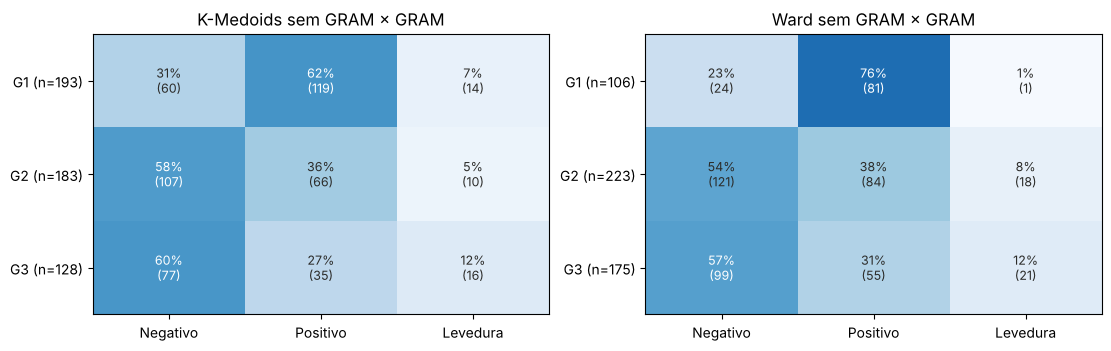

In [12]:
externas = {}
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
for ax, (nome, rotulos) in zip(eixos, particoes.items()):
    grupos = rotulos[conhecido]
    homogeneidade, completude, v_measure = homogeneity_completeness_v_measure(gram, grupos)
    externas[nome] = {
        "ARI": adjusted_rand_score(gram, grupos),
        "NMI": normalized_mutual_info_score(gram, grupos),
        "Homogeneidade": homogeneidade,
        "Completude": completude,
        "V-measure": v_measure,
    }
    tabela = pd.crosstab(grupos, gram).reindex(columns=["Negativo", "Positivo", "Levedura"])
    percentual = tabela.div(tabela.sum(axis=1), axis=0)
    ax.imshow(percentual.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (i, j), valor in np.ndenumerate(percentual.to_numpy()):
        cor_texto = "white" if valor > 0.55 else "#2b2b29"
        ax.text(j, i, f"{valor:.0%}\n({tabela.iat[i, j]})", ha="center", va="center", fontsize=9, color=cor_texto)
    ax.set_xticks(range(3), tabela.columns)
    ax.set_yticks(range(K), [f"{nomes_grupos[g]} (n={tabela.iloc[g].sum()})" for g in range(K)])
    ax.set_title(f"{nome} sem GRAM × GRAM")
plt.show()

print(pd.DataFrame(externas).T.round(3).to_string())
print("\nComposição da coleção:", pd.Series(gram).value_counts(normalize=True).round(3).to_dict())

A concordância com o `GRAM` é baixa nos dois métodos: o ARI fica em 0,058 no K-Medoids e 0,045 no Ward, e o NMI fica abaixo de 0,07. Ainda assim, há uma tendência. O G1 concentra Gram positivos (62% no K-Medoids e 76% no Ward, contra 44% na coleção), enquanto os G2 e G3 têm maioria de Gram negativos. As leveduras aparecem um pouco mais no G3 (12%, contra 8% na coleção) e quase não aparecem no G1 do Ward (1 registro).

Um valor externo baixo não significa que o agrupamento esteja errado. Os isolados se organizam principalmente pelo perfil de resposta aos ensaios, e esse perfil só se relaciona em parte com o tipo celular.

## Estabilidade

Medimos a estabilidade de duas formas. Para o K-Medoids, rodamos o PAM com 30 sementes diferentes, cada uma com uma única inicialização, e comparamos cada resultado com a partição final pelo ARI. O Ward é determinístico e não depende de semente. Para os dois métodos, sorteamos 30 subamostras com 80% dos registros, refazemos o agrupamento em cada uma e calculamos o ARI com a partição completa nos registros sorteados. Nas subamostras, a matriz é a mesma; só os registros mudam.

                            Média  Mínimo  1º quartil  Mediana  Máximo
K-Medoids, sementes         1.000   1.000       1.000    1.000   1.000
K-Medoids, subamostras 80%  0.655   0.282       0.358    0.693   1.000
Ward, subamostras 80%       0.398   0.148       0.285    0.408   0.616


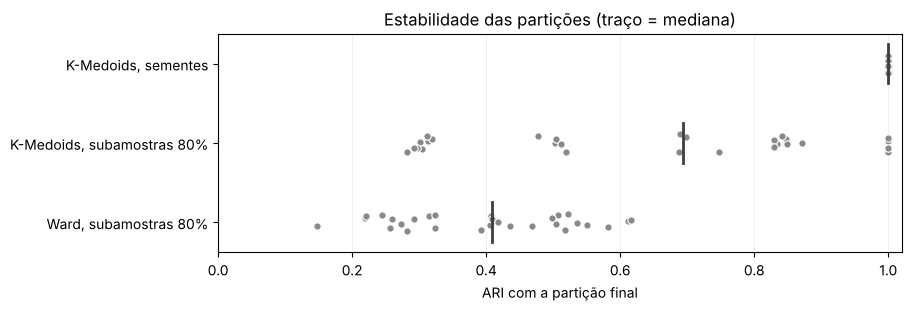

In [13]:
rng = np.random.default_rng(SEMENTE)
ari_sementes = [adjusted_rand_score(rotulos_km, k_medoids(distancias, K, semente)[0]) for semente in range(1000, 1030)]
ari_sub_km, ari_sub_hc = [], []
tamanho_sub = int(0.8 * n_registros)
for repeticao in range(30):
    indices = np.sort(rng.choice(n_registros, size=tamanho_sub, replace=False))
    sub_km = melhor_k_medoids(distancias[np.ix_(indices, indices)], K, inicializacoes=5, semente=2000 + 10 * repeticao)[0]
    sub_hc = fcluster(linkage(matriz[indices], method="ward"), K, criterion="maxclust")
    ari_sub_km.append(adjusted_rand_score(rotulos_km[indices], sub_km))
    ari_sub_hc.append(adjusted_rand_score(rotulos_hc[indices], sub_hc))

estabilidade = {
    "K-Medoids, sementes": ari_sementes,
    "K-Medoids, subamostras 80%": ari_sub_km,
    "Ward, subamostras 80%": ari_sub_hc,
}
resumo_estabilidade = pd.DataFrame({
    nome: pd.Series(valores).describe()[["mean", "min", "25%", "50%", "max"]] for nome, valores in estabilidade.items()
}).T.set_axis(["Média", "Mínimo", "1º quartil", "Mediana", "Máximo"], axis=1)
print(resumo_estabilidade.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
for posicao, (nome, valores) in enumerate(estabilidade.items()):
    deslocamento = np.random.default_rng(posicao).uniform(-0.12, 0.12, len(valores))
    ax.scatter(valores, posicao + deslocamento, s=28, color=cinza, edgecolor="white", linewidth=0.8)
    ax.plot([np.median(valores)] * 2, [posicao - 0.25, posicao + 0.25], color=tinta, linewidth=2)
ax.set_yticks(range(len(estabilidade)), list(estabilidade))
ax.invert_yaxis()
ax.set(xlim=(0, 1.02), xlabel="ARI com a partição final", title="Estabilidade das partições (traço = mediana)")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
plt.show()

**Sementes.** As 30 execuções do K-Medoids com sementes diferentes chegam todas à mesma partição (ARI = 1). Com os dados completos, o resultado não depende do sorteio inicial.

**Subamostras.** O K-Medoids tem mediana de 0,693, mas o ARI varia de 0,282 a 1. Os valores se agrupam em alguns níveis: em parte das subamostras a partição se repete quase igual, e em outras os três grupos são divididos de outro jeito. O Ward é menos estável, com mediana de 0,408 e máximo de 0,616.

Essa estabilidade moderada, junto com a silhueta baixa, confirma que a coleção não tem fronteiras naturais nítidas. Os três perfis aparecem nos dois métodos e são interpretáveis, mas a fronteira exata entre eles depende de quais registros entram na análise. Por isso não devemos tratar a pertença de um registro individual de fronteira como definitiva.

## Classificador

Treinamos uma floresta aleatória para prever o grupo de cada registro a partir dos mesmos atributos usados no agrupamento, com validação cruzada estratificada de 5 partes. A referência é a acurácia de sempre prever o grupo mais frequente. A importância dos atributos indica quais colunas mais separam os grupos.

In [14]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
resultado_classificador = {}
importancias = {}
for nome, rotulos in particoes.items():
    floresta = RandomForestClassifier(n_estimators=300, random_state=SEMENTE)
    acuracias = cross_val_score(floresta, X_sem_gram, rotulos, cv=validacao, scoring="accuracy")
    resultado_classificador[nome] = {
        "Acurácia média": acuracias.mean(),
        "Desvio padrão": acuracias.std(),
        "Referência (grupo mais frequente)": np.bincount(rotulos).max() / len(rotulos),
    }
    importancias[nome] = pd.Series(floresta.fit(X_sem_gram, rotulos).feature_importances_, index=X_sem_gram.columns)

print(pd.DataFrame(resultado_classificador).T.round(3).to_string())
print("\nAtributos mais importantes para separar os grupos")
print(pd.DataFrame({nome: serie.nlargest(10).index for nome, serie in importancias.items()}, index=range(1, 11)).to_string())

           Acurácia média  Desvio padrão  Referência (grupo mais frequente)
K-Medoids           0.893          0.031                              0.383
Ward                0.901          0.022                              0.441

Atributos mais importantes para separar os grupos
       K-Medoids          Ward
1   Atividade 15  Atividade 02
2   Atividade 20  Atividade 15
3   Atividade 21  Atividade 23
4   Atividade 09  Atividade 09
5   Atividade 23  Atividade 20
6   Atividade 02  Atividade 14
7   Atividade 11  Atividade 17
8   Atividade 14  Atividade 11
9   Atividade 17  Atividade 12
10  Atividade 10  Atividade 10


A floresta aleatória acerta o grupo em 89,3% dos casos no K-Medoids e em 90,1% no Ward. A referência de prever sempre o grupo mais frequente é de 38,3% e 44,1%. Os grupos podem ser reaprendidos a partir dos atributos, e os atributos que mais pesam são as atividades 15, 20, 21, 09, 23 e 02 no K-Medoids, e 02, 15, 23 e 09 no Ward. São as mesmas atividades usadas para nomear os grupos, e nenhuma coluna de morfologia aparece entre as dez mais importantes.

Esse resultado precisa ser lido com cuidado. As partições foram definidas por cortes no próprio espaço dos atributos, então mesmo cortes arbitrários de um contínuo tendem a ser reaprendidos com acurácia alta. O classificador mostra que os grupos são descritíveis por poucas atividades, mas não prova que existam fronteiras naturais. Essa questão é respondida pela silhueta e pela estabilidade.

## Exportação dos rótulos

Os rótulos ficam em `outputs/agrupamento/rotulos_grupos.tab`, na mesma ordem de `referencia_registros.tab`, para colorir as projeções da Tarefa B.

In [15]:
rotulos_exportados = referencia[["n°", "GRAM"]].assign(
    grupo_kmedoids=[nomes_grupos[g] for g in rotulos_km],
    grupo_ward=[nomes_grupos[g] for g in rotulos_hc],
    grupo_kmedoids_com_gram=[nomes_grupos[g] for g in rotulos_km_com],
    grupo_ward_com_gram=[nomes_grupos[g] for g in rotulos_hc_com],
)
pasta_saida.mkdir(parents=True, exist_ok=True)
arquivo_rotulos = pasta_saida / "rotulos_grupos.tab"
rotulos_exportados.to_csv(arquivo_rotulos, sep="\t", encoding="utf-8-sig", index=False)
releitura = pd.read_csv(arquivo_rotulos, sep="\t", encoding="utf-8-sig", dtype="string")
pd.testing.assert_frame_equal(releitura, rotulos_exportados.astype("string"))
print(f"{arquivo_rotulos} gerado: {len(rotulos_exportados)} registros.")

outputs/agrupamento/rotulos_grupos.tab gerado: 506 registros.


## Síntese da Tarefa A

- A coleção tem **estrutura de grupos fraca**. A silhueta não passa de 0,1 para nenhum *k*, e a estabilidade em subamostras é moderada no K-Medoids e baixa no Ward.
- Com *k* = 3, os dois métodos encontram **os mesmos três perfis de atividade**: alta resposta nas atividades 17 a 22 e na 02 (G1), baixa resposta nas atividades 13 a 23 (G2) e alta resposta nas atividades 14, 15 e 23 (G3). A morfologia quase não diferencia os grupos.
- O **K-Medoids** tem as melhores métricas internas e é mais estável. O **Ward** concorda com ele em 75,9% dos registros e diverge nos registros de fronteira, que deixa nos grupos onde os uniu nas primeiras etapas da árvore.
- O **GRAM** se relaciona pouco com os grupos (ARI ≤ 0,06), com uma tendência de Gram positivos no G1. Incluí-lo nos atributos muda pouco o K-Medoids, reorganiza o Ward e não aproxima os grupos do tipo celular.

# Tarefa B — Redução de Dimensionalidade

O objetivo é resumir os 23 ensaios em poucas dimensões e projetar os isolados num plano para visualizar a coleção. A entrada é a matriz `atividades`, gerada na transformação: atividades contínuas e ordinais padronizadas, com log nas atividades 14, 15 e 23, e atividades binárias em 0/1. A morfologia fica de fora porque a tarefa trata dos ensaios.

## Os dois métodos e suas premissas

**PCA (Análise de Componentes Principais).** Procura direções no espaço das 23 atividades ao longo das quais os dados variam mais. A primeira componente é a combinação linear das atividades com a maior variância; a segunda é a de maior variância entre as direções perpendiculares à primeira, e assim por diante. Cada componente é uma soma ponderada das atividades, então os eixos podem ser interpretados pelos pesos (cargas). A premissa é que as relações importantes são lineares e que variância alta significa informação. Como é uma rotação dos dados, permite reconstruí-los e medir o que se perde ao manter só *d* componentes. É determinística: não depende de semente.

**t-SNE (*t-distributed Stochastic Neighbor Embedding*).** Não procura direções. Para cada registro, calcula quais são os seus vizinhos próximos no espaço original e posiciona os pontos no plano de forma que esses vizinhos continuem próximos. A `perplexity` define, aproximadamente, quantos vizinhos cada ponto considera. O método preserva a vizinhança local, mas as distâncias entre grupos afastados e o tamanho aparente de cada grupo na figura não têm significado. Os eixos não têm interpretação, não há reconstrução, e o resultado depende da semente.

**Por que esses dois.** O enunciado pede pelo menos um método linear e um não linear. O PCA entrega eixos interpretáveis e métricas diretas de informação preservada. O t-SNE é o método não linear disponível no scikit-learn que mais se dedica a mostrar grupos locais. O contraste entre os dois mostra se a falta de separação vista na Tarefa A vem de uma limitação linear ou da própria estrutura dos dados.

In [16]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline

X_atividades = ler_tab("atividades")
assert list(X_atividades.columns) == atividades and len(X_atividades) == n_registros
matriz_atividades = X_atividades.to_numpy()
print(f"Matriz das atividades: {matriz_atividades.shape[0]} registros e {matriz_atividades.shape[1]} atributos.")

Matriz das atividades: 506 registros e 23 atributos.


## PCA: variância explicada e erro de reconstrução

A variância explicada mostra quanta informação cada componente carrega. O erro de reconstrução projeta os dados em *d* componentes, reconstrói as 23 colunas a partir delas e calcula o erro quadrático médio $\mathrm{MSE}(d) = \frac{1}{np}\sum_i \lVert x_i - \hat{x}_i^{(d)} \rVert^2$, para *d* de 1 a 23.

            Variância explicada  Acumulada  MSE da reconstrução
Componente                                                     
1                         0.192      0.192                0.679
2                         0.142      0.335                0.559
3                         0.092      0.427                0.482
4                         0.063      0.490                0.429
5                         0.057      0.547                0.381
6                         0.051      0.598                0.338
7                         0.045      0.643                0.300
8                         0.044      0.687                0.264
9                         0.042      0.728                0.229
10                        0.037      0.765                0.197
11                        0.036      0.801                0.167
12                        0.030      0.831                0.142
Componentes para 50% da variância: 5
Componentes para 70% da variância: 9
Componentes para 80% da variân

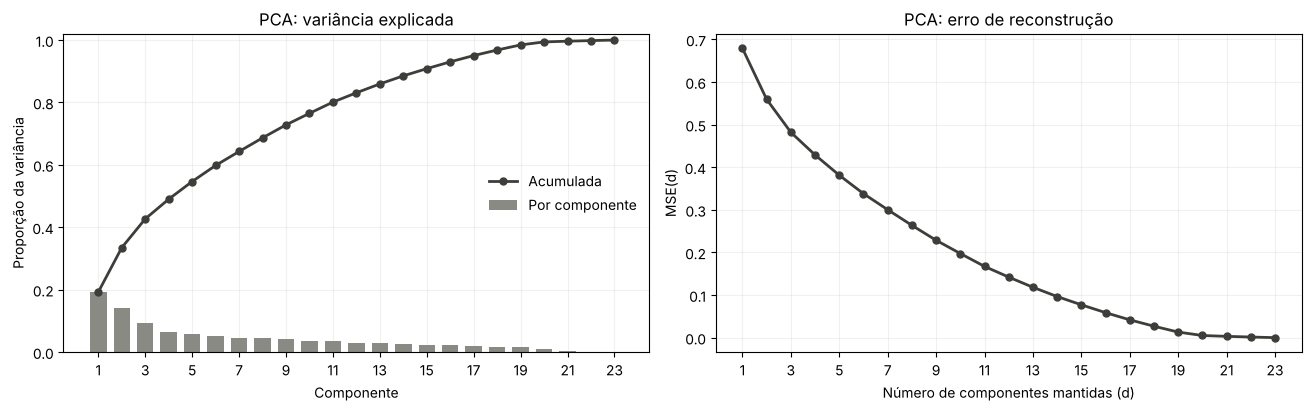

In [17]:
pca_completo = PCA(random_state=SEMENTE).fit(matriz_atividades)
variancia = pd.DataFrame({
    "Variância explicada": pca_completo.explained_variance_ratio_,
    "Acumulada": pca_completo.explained_variance_ratio_.cumsum(),
}, index=pd.RangeIndex(1, len(atividades) + 1, name="Componente"))

erro_reconstrucao = {}
for d in range(1, len(atividades) + 1):
    pca_d = PCA(n_components=d, random_state=SEMENTE).fit(matriz_atividades)
    reconstruida = pca_d.inverse_transform(pca_d.transform(matriz_atividades))
    erro_reconstrucao[d] = ((matriz_atividades - reconstruida) ** 2).mean()
variancia["MSE da reconstrução"] = pd.Series(erro_reconstrucao)
print(variancia.head(12).round(3).to_string())
for limiar in (0.5, 0.7, 0.8, 0.9):
    print(f"Componentes para {limiar:.0%} da variância: {int((variancia['Acumulada'] < limiar).sum() + 1)}")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax = eixos[0]
ax.bar(variancia.index, variancia["Variância explicada"], color=cinza, width=0.7, label="Por componente")
ax.plot(variancia.index, variancia["Acumulada"], color=tinta, linewidth=2, marker="o", markersize=5, label="Acumulada")
ax.set(title="PCA: variância explicada", xlabel="Componente", ylabel="Proporção da variância", ylim=(0, 1.02))
ax.legend(frameon=False, loc="center right")
ax = eixos[1]
ax.plot(variancia.index, variancia["MSE da reconstrução"], color=tinta, linewidth=2, marker="o", markersize=5)
ax.set(title="PCA: erro de reconstrução", xlabel="Número de componentes mantidas (d)", ylabel="MSE(d)")
for ax in eixos:
    ax.set_xticks(range(1, len(atividades) + 1, 2))
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
plt.show()

**Variância explicada.** Nenhuma componente domina. A primeira explica 19,2% da variância e a segunda, 14,2%; juntas, 33,5%. Depois disso, cada componente acrescenta menos de 10%, e são necessárias 5 componentes para 50% da variância, 11 para 80% e 15 para 90%. A informação dos 23 ensaios está espalhada por muitas direções, então o plano das duas primeiras componentes mostra só um terço da variação da coleção.

**Erro de reconstrução.** O MSE cai de 0,679 com uma componente para 0,559 com duas e 0,167 com onze, e chega a zero com as 23. A curva desce de forma suave, sem um ponto a partir do qual as componentes extras deixem de ajudar. Isso confirma que não há um número pequeno de dimensões que resuma bem os ensaios. Para visualizar, usamos duas; para uma representação mais fiel, seriam necessárias cerca de 11.

## PCA: o que cada eixo representa

As cargas são os pesos de cada atividade na componente. O sinal indica o sentido: atividades com cargas de mesmo sinal crescem juntas ao longo do eixo. A figura mostra as duas primeiras componentes, que formam o plano da projeção.

Maiores cargas em módulo
Componente 1: 20 (+0.36), 17 (+0.34), 22 (+0.33), 21 (+0.33), 18 (+0.31), 06 (-0.30)
Componente 2: 09 (+0.42), 11 (+0.39), 12 (+0.38), 15 (+0.36), 10 (+0.33), 14 (+0.29)


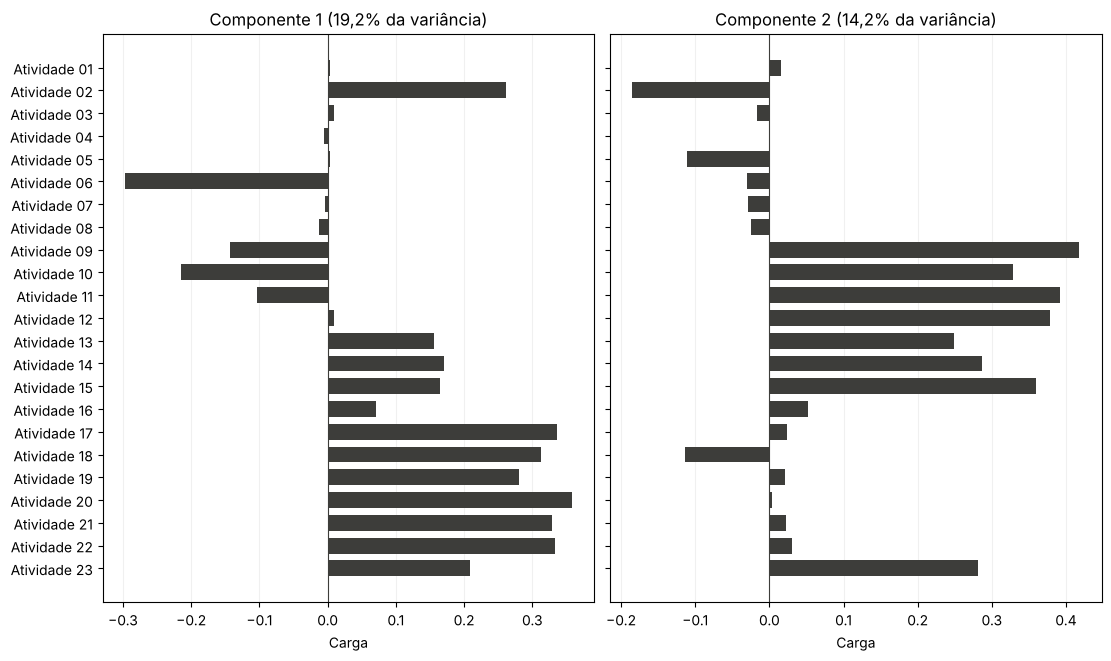

In [18]:
cargas = pd.DataFrame(
    pca_completo.components_[:2].T, index=atividades, columns=["Componente 1", "Componente 2"]
)
fig, eixos = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True, layout="constrained")
for ax, coluna in zip(eixos, cargas.columns):
    valores = cargas[coluna]
    ax.barh(atividades, valores, color=tinta, height=0.7)
    ax.axvline(0, color=tinta, linewidth=0.8)
    percentual = variancia.loc[int(coluna.split()[-1]), "Variância explicada"]
    ax.set(title=f"{coluna} ({percentual:.1%} da variância)".replace(".", ","), xlabel="Carga")
    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)
eixos[0].invert_yaxis()
plt.show()

print("Maiores cargas em módulo")
for coluna in cargas.columns:
    principais = cargas[coluna].reindex(cargas[coluna].abs().sort_values(ascending=False).index[:6])
    print(f"{coluna}: " + ", ".join(f"{nome.split()[-1]} ({valor:+.2f})" for nome, valor in principais.items()))

**Componente 1.** As maiores cargas positivas são das atividades 17 a 22 (entre +0,28 e +0,36), seguidas da 02 e da 23. As maiores cargas negativas são das atividades 06 (−0,30) e 10. O eixo vai de isolados com resposta baixa nas atividades 17 a 22 até isolados com resposta alta nelas, que é exatamente o que separa o G2 do G1 na Tarefa A.

**Componente 2.** As maiores cargas são das atividades 09 a 12 (entre +0,33 e +0,42) e das atividades 14, 15 e 23. A Atividade 02 tem carga negativa (−0,19). O eixo mede a resposta nas atividades 09 a 15 e 23, que é o perfil do G3.

As cargas também confirmam os blocos de correlação vistos na exploração: as atividades 17 a 22 andam juntas, assim como 09 a 12 e 14 e 15.

## Projeções em duas dimensões

A projeção do PCA usa as duas primeiras componentes. O t-SNE usa `perplexity = 30`, inicialização pela PCA e a semente fixa do projeto. As figuras ficam lado a lado e os pontos são pintados pelos grupos das duas abordagens da Tarefa A. Os grupos foram formados com as atividades e a morfologia, e as projeções usam só as atividades.

Silhueta dos grupos da Tarefa A medida no plano de cada projeção
                       PCA  t-SNE
Grupos do K-Medoids  0.347  0.317
Grupos do Ward       0.302  0.295


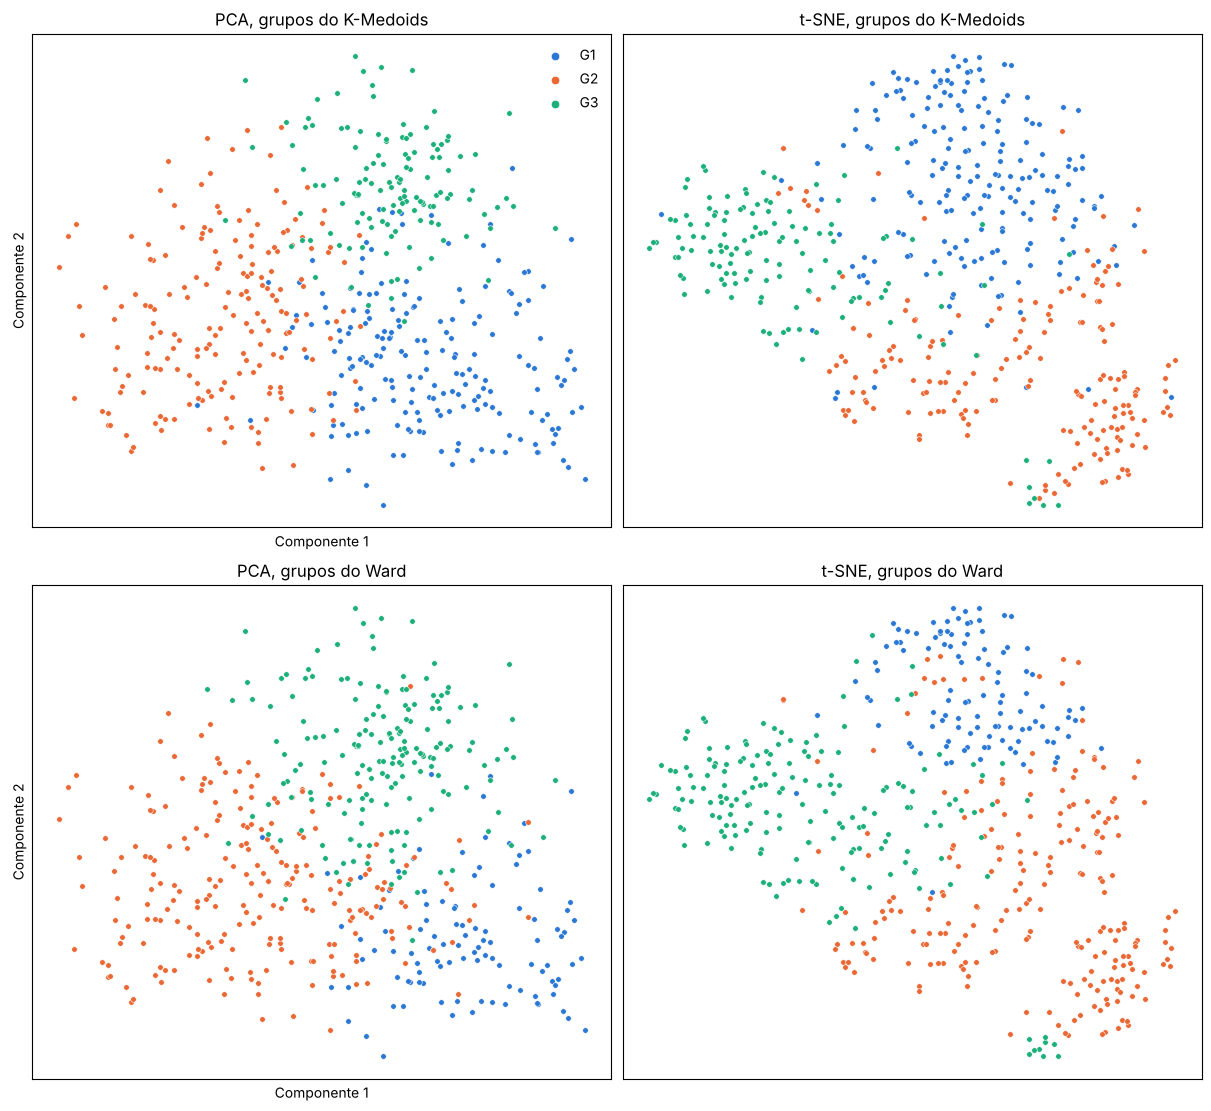

In [19]:
PERPLEXIDADE = 30

def rodar_tsne(perplexidade=PERPLEXIDADE, semente=SEMENTE, inicio="pca"):
    return TSNE(
        n_components=2, perplexity=perplexidade, init=inicio, learning_rate="auto",
        random_state=semente,
    ).fit_transform(matriz_atividades)

projecoes = {
    "PCA": PCA(n_components=2, random_state=SEMENTE).fit_transform(matriz_atividades),
    "t-SNE": rodar_tsne(),
}

def desenhar(ax, coordenadas, rotulos, titulo):
    for g in range(K):
        pontos = coordenadas[rotulos == g]
        ax.scatter(pontos[:, 0], pontos[:, 1], s=16, color=cores_grupos[g], edgecolor="white",
                   linewidth=0.4, label=f"{nomes_grupos[g]}")
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])

fig, eixos = plt.subplots(2, 2, figsize=(12, 11), layout="constrained")
for linha, (nome_particao, rotulos) in enumerate(particoes.items()):
    for coluna, (nome_projecao, coordenadas) in enumerate(projecoes.items()):
        desenhar(eixos[linha, coluna], coordenadas, rotulos, f"{nome_projecao}, grupos do {nome_particao}")
eixos[0, 0].set(xlabel="Componente 1", ylabel="Componente 2")
eixos[1, 0].set(xlabel="Componente 1", ylabel="Componente 2")
eixos[0, 0].legend(frameon=False, loc="upper right", markerscale=1.5)
plt.show()

separacao = pd.DataFrame({
    nome_projecao: {nome: silhouette_score(coordenadas, rotulos) for nome, rotulos in particoes.items()}
    for nome_projecao, coordenadas in projecoes.items()
})
separacao.index = [f"Grupos do {nome}" for nome in separacao.index]
print("Silhueta dos grupos da Tarefa A medida no plano de cada projeção")
print(separacao.round(3).to_string())

**PCA.** Os três grupos ocupam regiões distintas e contíguas do plano: o G2 à esquerda, onde a resposta nas atividades 17 a 22 é baixa; o G1 embaixo à direita; e o G3 em cima, onde a Componente 2 é alta. Não há espaços vazios entre as regiões. Os pontos formam uma única nuvem, e os grupos são faixas dessa nuvem, o que combina com a silhueta baixa da Tarefa A.

**t-SNE.** A figura mostra mais detalhe local. O G3 forma uma região à esquerda, o G1 ocupa a parte de cima e o G2 se divide entre uma faixa no meio e uma ilha mais densa embaixo à direita. Mesmo assim, as regiões continuam se tocando, sem lacunas claras entre os grupos.

**Grupos do Ward.** Nas duas projeções, o G2 do Ward invade a região do G1, porque o Ward colocou no G2 os registros de fronteira que o K-Medoids deixa no G1. O G1 do Ward ocupa só o núcleo da região do G1.

**Separação no plano.** A silhueta dos grupos do K-Medoids medida no plano é 0,347 na PCA e 0,317 no t-SNE. Esses valores são maiores que a silhueta de 0,098 no espaço original porque o plano tem só duas dimensões e os grupos se alinham com os dois primeiros eixos da PCA. Ao contrário do que costuma acontecer, o t-SNE não separa melhor os grupos que a PCA: os grupos da Tarefa A seguem as direções de maior variância, que a PCA captura bem.

## Trustworthiness

A *trustworthiness* vai de 0 a 1 e mede se os pontos que aparecem vizinhos na figura também eram vizinhos no espaço original das 23 atividades. Um valor baixo indica que a figura junta pontos que na verdade estavam longe. Calculamos para 5, 10 e 30 vizinhos. Como referência, incluímos a PCA com as componentes necessárias para 80% da variância.

In [20]:
d_80 = int((variancia["Acumulada"] < 0.8).sum() + 1)
espacos = {
    "PCA 2D": projecoes["PCA"],
    f"PCA {d_80}D (80% da variância)": PCA(n_components=d_80, random_state=SEMENTE).fit_transform(matriz_atividades),
    "t-SNE 2D": projecoes["t-SNE"],
}
confiabilidade = pd.DataFrame({
    f"{k} vizinhos": {nome: trustworthiness(matriz_atividades, coordenadas, n_neighbors=k) for nome, coordenadas in espacos.items()}
    for k in (5, 10, 30)
})
print(confiabilidade.round(3).to_string())

                            5 vizinhos  10 vizinhos  30 vizinhos
PCA 2D                           0.803        0.803        0.818
PCA 11D (80% da variância)       0.987        0.985        0.982
t-SNE 2D                         0.957        0.932        0.896


O t-SNE preserva melhor a vizinhança na figura: a trustworthiness é 0,957 com 5 vizinhos e 0,932 com 10, contra cerca de 0,80 da PCA em 2D. A vantagem do t-SNE diminui quando se olham vizinhanças maiores (0,896 com 30 vizinhos), o que é esperado de um método que prioriza a estrutura local. A PCA com 11 componentes chega a 0,98, mas não pode ser desenhada. Na PCA em 2D, o valor de 0,80 indica que a figura coloca lado a lado vários pontos que estavam afastados no espaço original, porque o plano descarta dois terços da variância.

## Estabilidade do t-SNE

O PCA é determinístico, então rodar de novo produz a mesma figura. O t-SNE principal também é: com a inicialização pela PCA, a semente não altera o resultado. Para medir o quanto a figura depende do ponto de partida, fazemos dois testes. Primeiro, rodamos o t-SNE com início aleatório e cinco sementes diferentes, com `perplexity = 30`, e medimos, para cada ponto, a fração dos seus 10 vizinhos mais próximos na figura que coincide com os 10 vizinhos na figura de referência. Depois, variamos a `perplexity` entre 5, 15, 30 e 50 e comparamos as figuras, a trustworthiness e a silhueta dos grupos do K-Medoids no plano.

t-SNE com início aleatório e sementes diferentes (perplexity = 30)
         Vizinhos em comum com a referência  Trustworthiness (10)  Silhueta K-Medoids
Semente                                                                              
1                                     0.626                 0.930               0.276
2                                     0.647                 0.933               0.304
3                                     0.626                 0.932               0.304
4                                     0.683                 0.936               0.313
5                                     0.627                 0.932               0.310

Para comparação, vizinhos em comum entre a PCA 2D e o t-SNE: 0.169

t-SNE com perplexity diferentes
            Trustworthiness (10)  Trustworthiness (30)  Silhueta K-Medoids  Vizinhos em comum com perplexity 30
Perplexity                                                                                                     
5     

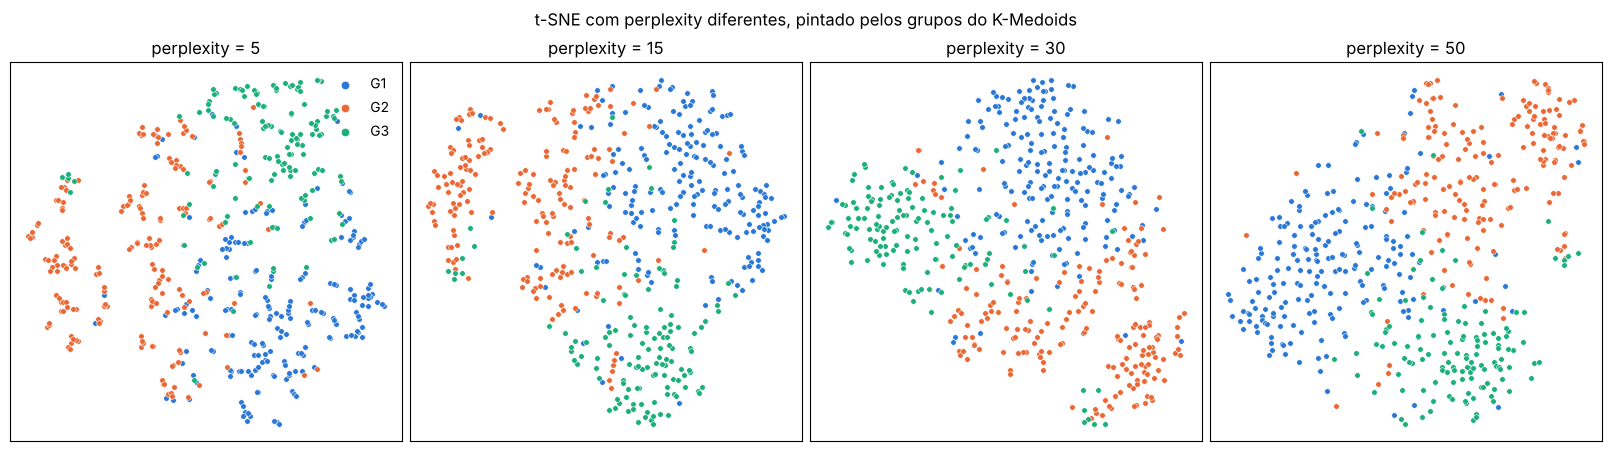

In [21]:
def vizinhos(coordenadas, k=10):
    indices = NearestNeighbors(n_neighbors=k + 1).fit(coordenadas).kneighbors(coordenadas, return_distance=False)
    return indices[:, 1:]

def vizinhos_em_comum(a, b, k=10):
    va, vb = vizinhos(a, k), vizinhos(b, k)
    return np.mean([len(set(x) & set(y)) / k for x, y in zip(va, vb)])

referencia_tsne = projecoes["t-SNE"]
sementes_teste = [1, 2, 3, 4, 5]
por_semente = pd.DataFrame([
    {
        "Semente": semente,
        "Vizinhos em comum com a referência": vizinhos_em_comum(referencia_tsne, coordenadas),
        "Trustworthiness (10)": trustworthiness(matriz_atividades, coordenadas, n_neighbors=10),
        "Silhueta K-Medoids": silhouette_score(coordenadas, rotulos_km),
    }
    for semente, coordenadas in ((s, rodar_tsne(semente=s, inicio="random")) for s in sementes_teste)
]).set_index("Semente")
print("t-SNE com início aleatório e sementes diferentes (perplexity = 30)")
print(por_semente.round(3).to_string())
print(f"\nPara comparação, vizinhos em comum entre a PCA 2D e o t-SNE: {vizinhos_em_comum(referencia_tsne, projecoes['PCA']):.3f}")

perplexidades = [5, 15, 30, 50]
figuras_perplexidade = {p: (referencia_tsne if p == PERPLEXIDADE else rodar_tsne(perplexidade=p)) for p in perplexidades}
por_perplexidade = pd.DataFrame([
    {
        "Perplexity": p,
        "Trustworthiness (10)": trustworthiness(matriz_atividades, coordenadas, n_neighbors=10),
        "Trustworthiness (30)": trustworthiness(matriz_atividades, coordenadas, n_neighbors=30),
        "Silhueta K-Medoids": silhouette_score(coordenadas, rotulos_km),
        "Vizinhos em comum com perplexity 30": vizinhos_em_comum(referencia_tsne, coordenadas),
    }
    for p, coordenadas in figuras_perplexidade.items()
]).set_index("Perplexity")
print("\nt-SNE com perplexity diferentes")
print(por_perplexidade.round(3).to_string())

fig, eixos = plt.subplots(1, 4, figsize=(16, 4.4), layout="constrained")
for ax, (p, coordenadas) in zip(eixos, figuras_perplexidade.items()):
    desenhar(ax, coordenadas, rotulos_km, f"perplexity = {p}")
eixos[0].legend(frameon=False, loc="upper right", markerscale=1.5)
fig.suptitle("t-SNE com perplexity diferentes, pintado pelos grupos do K-Medoids")
plt.show()

**Sementes.** Com início aleatório, as figuras mudam de arranjo: em média, só 63% a 68% dos 10 vizinhos de cada ponto se repetem em relação à figura de referência. A qualidade não muda: a trustworthiness fica entre 0,930 e 0,936 e a silhueta dos grupos, entre 0,28 e 0,31. A posição exata de cada região no plano é arbitrária, mas a vizinhança local e a organização em três regiões se mantêm. Para comparação, a PCA e o t-SNE compartilham só 17% dos vizinhos, porque os dois métodos organizam o plano de formas muito diferentes.

**Perplexity.** Com `perplexity = 5`, o t-SNE fragmenta a coleção em muitos aglomerados pequenos, que refletem vizinhanças muito locais e não grupos reais. Com 15, 30 e 50, as três regiões dos grupos aparecem de forma consistente, embora em posições diferentes. A trustworthiness com 10 vizinhos varia pouco (0,913 a 0,935) e é ligeiramente maior com perplexity mais alta. Escolhemos 30 porque está no meio da faixa estável e tem trustworthiness praticamente igual à de 50.

## Utilidade da redução

Para medir quanto da informação útil sobrevive à redução, treinamos uma regressão logística para prever duas coisas a partir de cada representação: o `GRAM` (504 registros com tipo conhecido) e o grupo do K-Medoids. Comparamos as 23 atividades originais, a PCA com 2 componentes, a PCA com as componentes para 80% da variância e o t-SNE em 2D. A validação cruzada é estratificada, com 5 partes. A PCA é ajustada dentro de cada parte de treino. O t-SNE não projeta pontos novos, então é calculado uma vez com todos os registros; isso favorece um pouco o t-SNE nessa comparação.

In [22]:
def acuracia(X, y, reduzir=None):
    etapas = ([PCA(n_components=reduzir, random_state=SEMENTE)] if reduzir else []) + [LogisticRegression(max_iter=2000)]
    validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
    return cross_val_score(make_pipeline(*etapas), X, y, cv=validacao, scoring="accuracy").mean()

alvos = {
    "GRAM": (conhecido, referencia["GRAM"].to_numpy()),
    "Grupo do K-Medoids": (np.ones(n_registros, dtype=bool), rotulos_km),
}
utilidade = {}
for nome_alvo, (mascara, y) in alvos.items():
    y = y[mascara]
    utilidade[nome_alvo] = {
        "23 atividades": acuracia(matriz_atividades[mascara], y),
        "PCA 2D": acuracia(matriz_atividades[mascara], y, reduzir=2),
        f"PCA {d_80}D": acuracia(matriz_atividades[mascara], y, reduzir=d_80),
        "t-SNE 2D": acuracia(projecoes["t-SNE"][mascara], y),
        "Grupo mais frequente": pd.Series(y).value_counts(normalize=True).iloc[0],
    }
print("Acurácia média na validação cruzada")
print(pd.DataFrame(utilidade).round(3).to_string())

Acurácia média na validação cruzada
                       GRAM  Grupo do K-Medoids
23 atividades         0.655               0.954
PCA 2D                0.579               0.877
PCA 11D               0.629               0.937
t-SNE 2D              0.619               0.834
Grupo mais frequente  0.484               0.383


**Grupo do K-Medoids.** As 23 atividades preveem o grupo com 95,4% de acurácia. A PCA com 11 componentes perde pouco (93,7%), a PCA em 2D cai para 87,7% e o t-SNE para 83,4%. Com só duas dimensões, a PCA guarda mais informação sobre os grupos que o t-SNE, o que combina com a silhueta no plano.

**GRAM.** Prever o tipo celular a partir dos ensaios é mais difícil: 65,5% com as 23 atividades, contra 48,4% de prever sempre o tipo mais frequente. As reduções perdem parte dessa informação (57,9% na PCA em 2D, 61,9% no t-SNE e 62,9% na PCA com 11 componentes). O t-SNE vai melhor que a PCA em 2D nessa tarefa porque preserva vizinhanças locais, mas ele foi calculado com todos os registros, o que o favorece um pouco nessa comparação.

Em resumo, as duas dimensões servem para visualizar a coleção, mas uma análise que dependa de informação mais fina deve usar a PCA com cerca de 11 componentes ou as atividades originais.

## Síntese da Tarefa B

- **A informação dos ensaios está espalhada.** As duas primeiras componentes da PCA explicam 33,5% da variância, e são necessárias 11 para 80%. Não existe um resumo em poucas dimensões que preserve quase tudo.
- **Os eixos da PCA têm leitura clara.** A Componente 1 mede a resposta nas atividades 17 a 22, e a Componente 2 mede a resposta nas atividades 09 a 15 e 23. Esses são exatamente os eixos que distinguem os três grupos da Tarefa A.
- **As duas projeções contam a mesma história.** Os três grupos aparecem como regiões contíguas de uma única nuvem, sem lacunas entre elas. O t-SNE mostra mais detalhe local, como a ilha mais densa dentro do G2, mas não revela grupos separados que a PCA esconda.
- **O t-SNE preserva melhor a vizinhança** (trustworthiness de 0,93 contra 0,80), e a **PCA preserva melhor a organização dos grupos** (silhueta no plano de 0,35 contra 0,32 e acurácia de 87,7% contra 83,4%). O t-SNE muda de arranjo com a semente e a perplexity, mas mantém a qualidade e as três regiões.